# Deliverable 3: Exploratory Data Analysis
**Project:** The Role of Data Analytics in Identifying Revenue Collection Leakages at Forbes Border Post, Zimbabwe
**Notebook:** 02 – Exploratory analysis of revenue gaps, inspections, risk profiling, targets and importers

**Questions this notebook answers (from the README objectives and the project proposal):**
1. How big is the potential revenue gap, and how much of it is recovered?
2. Does the current `Risk_Category` (Low / Medium / High) point inspectors to the right shipments?
3. Which countries of origin and commodities contribute most to the gap?
4. Which offence types cost the most?
5. How does revenue compare with the monthly **targets**, and how does the gap move over the year?
6. How much revenue sits in *Part-paid* or *Pending* declarations?
7. Which importers should be on a watchlist?

**Input:** `data/processed/cleaned_customs_transactions.csv` and `monthly_targets.csv`, both produced by notebook 01.

> **Reminder:** `Potential_Revenue_Gap_USD` is the difference between what customs assessed and what the importer declared. It is an **indicator of possible leakage, not proof of fraud**, and the data is simulated.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style for professional-looking charts
sns.set_theme(style="whitegrid")

# Load the cleaned data produced by notebook 01
df = pd.read_csv('../data/processed/cleaned_customs_transactions.csv')
targets = pd.read_csv('../data/processed/monthly_targets.csv')

# Restore types lost when saving to CSV
df['Declaration_Date'] = pd.to_datetime(df['Declaration_Date'])
df['Risk_Category'] = pd.Categorical(df['Risk_Category'], categories=['Low', 'Medium', 'High'], ordered=True)
df['Month'] = df['Month'].astype(str)
targets['Month'] = targets['Month'].astype(str)

print(f"Data loaded: {len(df)} declarations from {df['Declaration_Date'].min().date()} "
      f"to {df['Declaration_Date'].max().date()} ({df['Month'].nunique()} months). Ready for analysis.")

Data loaded: 480 declarations from 2025-01-01 to 2025-12-30 (12 months). Ready for analysis.


## 1. Headline revenue metrics

In [2]:
# 1. Total Assessed Revenue (what should have been collected)
total_assessed = df['Assessed_Total_Revenue_USD'].sum()
total_declared = df['Declared_Total_Revenue_USD'].sum()

# 2. Total Potential Revenue Gap (what was under-declared)
total_gap = df['Potential_Revenue_Gap_USD'].sum()

# 3. Total Additional Revenue Recovered (what was actually recovered)
total_recovered = df['Additional_Revenue_Recovered_USD'].sum()

# 4. Recovery Rate (share of the gap successfully recovered)
recovery_rate = (total_recovered / total_gap) * 100 if total_gap > 0 else 0

print("--- KEY REVENUE METRICS ---")
print(f"Total Declared Revenue:             ${total_declared:,.2f}")
print(f"Total Assessed Revenue:             ${total_assessed:,.2f}")
print(f"Total Potential Revenue Gap:        ${total_gap:,.2f}  ({total_gap / total_assessed * 100:.2f}% of assessed revenue)")
print(f"Total Additional Revenue Recovered: ${total_recovered:,.2f}")
print(f"Recovery Rate:                      {recovery_rate:.2f}%")
print(f"Unrecovered gap:                    ${total_gap - total_recovered:,.2f}")

--- KEY REVENUE METRICS ---
Total Declared Revenue:             $872,288.68
Total Assessed Revenue:             $905,752.62
Total Potential Revenue Gap:        $33,801.23  (3.73% of assessed revenue)
Total Additional Revenue Recovered: $9,056.99
Recovery Rate:                      26.79%
Unrecovered gap:                    $24,744.24


### Interpretation: headline metrics
* Customs assessed **$905,753** in revenue. Importers declared **$872,289**, so the **potential revenue gap is $33,801**, which is **3.7% of assessed revenue**. Leakage is modest relative to total collections, but it is concentrated in specific areas (shown below), which makes it worth targeting.
* Only **$9,057 (26.8%) of the gap was recovered**, leaving **$24,744 unrecovered**.
* **Caution about the 26.8% figure:** it is easy to read this as *"customs is bad at collecting what it finds."* The next table shows that reading is wrong.

In [3]:
# Where does the gap sit? Split it by whether the declaration was inspected and whether an offence was found
df['Detection_Stage'] = np.select(
    [df['Inspection_Conducted'].eq('No'),
     df['Inspection_Conducted'].eq('Yes') & df['Offence_Detected'].eq('No'),
     df['Offence_Detected'].eq('Yes')],
    ['1. Not inspected', '2. Inspected – no offence found', '3. Inspected – offence detected'],
    default='Unknown')

gap_by_stage = df.groupby('Detection_Stage').agg(
    Declarations=('Declaration_ID', 'count'),
    With_Gap=('Has_Revenue_Gap', lambda s: (s == 'Yes').sum()),
    Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
    Recovered=('Additional_Revenue_Recovered_USD', 'sum'))
gap_by_stage['Share_of_Total_Gap_%'] = (gap_by_stage['Revenue_Gap'] / total_gap * 100).round(1)
gap_by_stage['Recovery_Rate_%'] = (gap_by_stage['Recovered'] / gap_by_stage['Revenue_Gap'] * 100).round(1)
display(gap_by_stage.round(2))

,Declarations,With_Gap,Revenue_Gap,Recovered,Share_of_Total_Gap_%,Recovery_Rate_%
Detection_Stage,,,,,,
1. Not inspected,324,87,22084.96,0.00,65.3,0.0
2. Inspected – no offence found,131,11,1107.85,0.00,3.3,0.0
3. Inspected – offence detected,25,25,10608.42,9056.99,31.4,85.4


### Interpretation: the gap is a *detection* problem, not a *collection* problem (key new finding)
This breakdown changes how the recovery rate should be read:

* **65% of the gap ($22,085) comes from 87 declarations that were never inspected.** Nobody looked at them, so nothing was recovered.
* Another **$1,108 (3%)** sat in 11 declarations that *were* inspected, yet no offence was recorded. These are probably assessment adjustments made without a formal offence.
* For the **25 declarations where an offence was detected, 85.4% of the gap was recovered** ($9,057 of $10,608).

**Implication:** once ZIMRA finds an under-declaration, it collects most of the money. The real leakage is the under-declaration it **never examines**. The recovery rate rises by **finding more cases** (better targeting of inspections), not mainly by chasing payments harder. The current report recommends *"stricter follow-up of Pending/Part-paid to raise recovery from 26.79% to 50%"*. That recommendation should be reframed: follow-up alone cannot move the rate much, because 65% of the gap never reaches the recovery stage.

## 2. Inspection effectiveness and risk profiling

In [4]:
# Cross-tabulation of Inspections vs Offences
inspection_effectiveness = pd.crosstab(df['Inspection_Conducted'], df['Offence_Detected'])

# Calculate the "Hit Rate" of inspections
inspections_yes = df[df['Inspection_Conducted'] == 'Yes']
offences_yes = inspections_yes[inspections_yes['Offence_Detected'] == 'Yes']
hit_rate = (len(offences_yes) / len(inspections_yes)) * 100

# How many inspected declarations actually had a revenue gap?
gap_in_inspected = (inspections_yes['Has_Revenue_Gap'] == 'Yes').sum()

print("--- INSPECTION EFFECTIVENESS ---")
print(f"Total Inspections Conducted: {len(inspections_yes)} ({len(inspections_yes) / len(df) * 100:.1f}% of declarations)")
print(f"Total Offences Found During Inspections: {len(offences_yes)}")
print(f"Inspection Hit Rate (Success Rate): {hit_rate:.2f}%")
print(f"Inspected declarations that had a revenue gap: {gap_in_inspected} "
      f"(of which {len(offences_yes)} were recorded as offences)")
print("\nBreakdown:")
display(inspection_effectiveness)

--- INSPECTION EFFECTIVENESS ---
Total Inspections Conducted: 156 (32.5% of declarations)
Total Offences Found During Inspections: 25
Inspection Hit Rate (Success Rate): 16.03%
Inspected declarations that had a revenue gap: 36 (of which 25 were recorded as offences)

Breakdown:


Offence_Detected,No,Yes
Inspection_Conducted,,
No,324,0
Yes,131,25


### Interpretation: inspection hit rate
* **156 of 480 declarations (32.5%) were physically inspected**, and **25 offences** were found, a **hit rate of 16.0%**. Roughly **5 of every 6 inspections find nothing**.
* **Offences are only ever recorded on inspected shipments** (0 offences among the 324 un-inspected). So "offence detected" measures **where we looked** as much as **where the problems are**. That is why the *revenue gap* (assessed vs declared) is a better measure of non-compliance than the offence count.
* Inspected declarations contained **36 under-declarations**, but only **25 were recorded as offences**. The remaining 11 were adjusted without an offence being recorded.

**Implication:** a 16% hit rate is not automatically "bad" (random checks have deterrence value), but it suggests inspection effort could be directed better. The next table tests whether the risk categories are doing that job.

In [5]:
# Does the risk category predict where the problems are?
risk_analysis = df.groupby('Risk_Category', observed=True).agg(
    Declarations=('Declaration_ID', 'count'),
    Inspections=('Inspection_Conducted', lambda s: (s == 'Yes').sum()),
    Offences=('Offence_Detected', lambda s: (s == 'Yes').sum()),
    Declarations_With_Gap=('Has_Revenue_Gap', lambda s: (s == 'Yes').sum()),
    Total_Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
    Avg_Gap_Per_Declaration=('Potential_Revenue_Gap_USD', 'mean'),
    Total_Recovered=('Additional_Revenue_Recovered_USD', 'sum'))
risk_analysis['Inspection_Rate_%'] = risk_analysis['Inspections'] / risk_analysis['Declarations'] * 100
risk_analysis['Hit_Rate_%'] = risk_analysis['Offences'] / risk_analysis['Inspections'] * 100
risk_analysis['Gap_Incidence_%'] = risk_analysis['Declarations_With_Gap'] / risk_analysis['Declarations'] * 100
risk_analysis['Share_of_Gap_%'] = risk_analysis['Total_Revenue_Gap'] / total_gap * 100
risk_analysis['Recovery_Rate_%'] = risk_analysis['Total_Recovered'] / risk_analysis['Total_Revenue_Gap'] * 100

print("--- RISK CATEGORY ANALYSIS ---")
display(risk_analysis.round(2))

--- RISK CATEGORY ANALYSIS ---


,Declarations,Inspections,Offences,Declarations_With_Gap,Total_Revenue_Gap,Avg_Gap_Per_Declaration,Total_Recovered,Inspection_Rate_%,Hit_Rate_%,Gap_Incidence_%,Share_of_Gap_%,Recovery_Rate_%
Risk_Category,,,,,,,,,,,,
Low,212,25,5,70,19771.70,93.26,2553.00,11.79,20.00,33.02,58.49,12.91
Medium,182,57,11,38,9161.57,50.34,3010.26,31.32,19.30,20.88,27.10,32.86
High,86,74,9,15,4867.96,56.60,3493.73,86.05,12.16,17.44,14.40,71.77


### Interpretation: the risk profile points the wrong way (core finding)
The risk categories decide **who gets inspected**, and on that they work as designed: **86% of High-risk** shipments are inspected versus only **12% of Low-risk** ones. But the categories do **not** match **where the under-declaration actually is**:

| | Low | Medium | High |
|---|---|---|---|
| Inspection rate | 12% | 31% | **86%** |
| % of declarations under-declared (gap incidence) | **33%** | 21% | 17% |
| Share of total gap | **58%** ($19,772) | 27% | 14% |
| Average gap per declaration | **$93** | $50 | $57 |
| Hit rate when inspected | 20% (5/25) | 19% (11/57) | **12%** (9/74) |
| Share of gap recovered | **13%** | 33% | 72% |

* **Low-risk shipments are the *most* likely to be under-declared** (1 in 3), have the **largest average gap**, and make up **58% of the total gap**. Because they are rarely inspected, **only 13% of their gap is recovered**.
* **High-risk shipments are inspected almost every time, yet have the *lowest* hit rate (12%)**. Most inspection resources go to the group with the fewest problems.
* This is **not** just a volume effect (Low has more declarations). Low is worse on **every per-declaration measure**, so the conclusion holds after adjusting for size.

**How sure are we?** (tested formally in notebook 03)
* The difference in **gap incidence** between risk categories is **statistically significant** (chi-square p = 0.004; Low vs the rest p = 0.001). The inverted risk profile is a real pattern, not chance.
* The **hit-rate** differences are **not** significant (p = 0.46), because they rest on only 25 offences. Present them as supporting evidence only.

**Implication:** the risk-profiling rules need **recalibrating**. Low-risk declarations should get a meaningful level of **random or analytics-driven checks**, and the ranking should be rebuilt from observed under-declaration rates. Notebook 03 builds and tests such a model: with the same 156 inspections, it would catch **42.7% of the gap instead of 34.7%**.

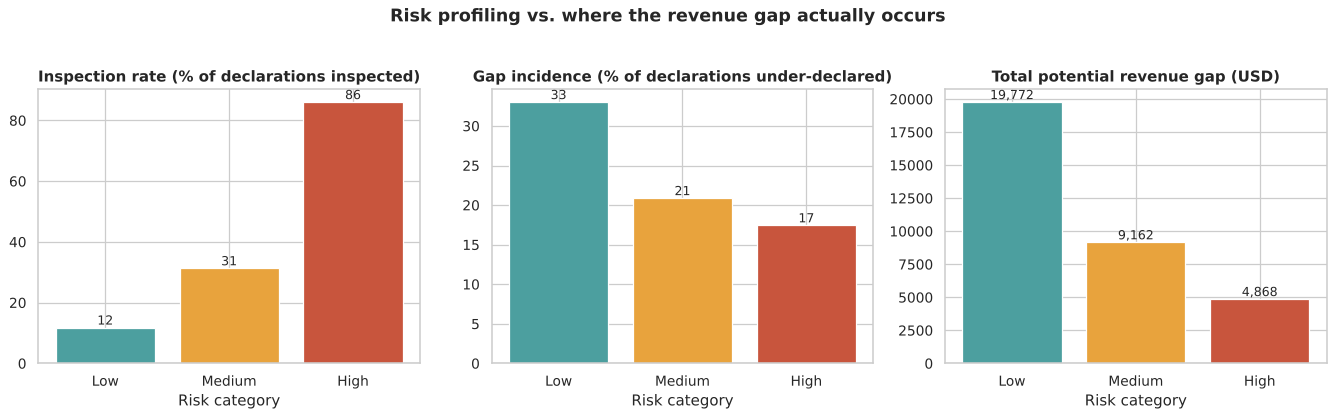

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
order = ['Low', 'Medium', 'High']
colors = ['#4C9F9F', '#E8A33D', '#C8553D']

axes[0].bar(order, risk_analysis.loc[order, 'Inspection_Rate_%'], color=colors)
axes[0].set_title('Inspection rate (% of declarations inspected)', fontweight='bold')

axes[1].bar(order, risk_analysis.loc[order, 'Gap_Incidence_%'], color=colors)
axes[1].set_title('Gap incidence (% of declarations under-declared)', fontweight='bold')

axes[2].bar(order, risk_analysis.loc[order, 'Total_Revenue_Gap'], color=colors)
axes[2].set_title('Total potential revenue gap (USD)', fontweight='bold')

for ax in axes:
    ax.set_xlabel('Risk category')
    for p in ax.patches:
        ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha='center', va='bottom', fontsize=10)
plt.suptitle('Risk profiling vs. where the revenue gap actually occurs', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../reports/risk_category_mismatch.png', bbox_inches='tight')
plt.show()

### Reading the chart
The three panels side by side show the mismatch: the **inspection rate rises** from Low → High (left), while **gap incidence and total gap fall** from Low → High (middle and right). In a well-calibrated system, all three would rise together. This chart is a strong candidate for the presentation, and it is saved as `reports/risk_category_mismatch.png`.

## 3. Where is the gap concentrated? Countries and commodities
Totals alone can mislead, because a country with more shipments will naturally have a larger total. So each table also shows **gap incidence** (% of declarations under-declared) and **average gap per declaration**.

In [7]:
def gap_table(col):
    t = df.groupby(col, observed=True).agg(
        Declarations=('Declaration_ID', 'count'),
        Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
        Gap_Incidence_pct=('Has_Revenue_Gap', lambda s: (s == 'Yes').mean() * 100),
        Avg_Gap_Per_Declaration=('Potential_Revenue_Gap_USD', 'mean'))
    t['Share_of_Gap_pct'] = t['Revenue_Gap'] / total_gap * 100
    return t.sort_values('Revenue_Gap', ascending=False).round(2)

print("--- COUNTRIES BY REVENUE GAP ---")
top_countries = gap_table('Country_of_Origin')
display(top_countries)

print("\n--- COMMODITIES BY REVENUE GAP ---")
top_commodities = gap_table('Commodity_Description')
display(top_commodities)

--- COUNTRIES BY REVENUE GAP ---


,Declarations,Revenue_Gap,Gap_Incidence_pct,Avg_Gap_Per_Declaration,Share_of_Gap_pct
Country_of_Origin,,,,,
Zambia,88,7838.03,26.14,89.07,23.19
South Africa,73,7515.84,32.88,102.96,22.24
China,90,6278.35,24.44,69.76,18.57
India,76,5220.26,26.32,68.69,15.44
United Arab Emirates,59,4557.11,27.12,77.24,13.48
Mozambique,94,2391.64,19.15,25.44,7.08



--- COMMODITIES BY REVENUE GAP ---


,Declarations,Revenue_Gap,Gap_Incidence_pct,Avg_Gap_Per_Declaration,Share_of_Gap_pct
Commodity_Description,,,,,
Tyres,51,5346.27,27.45,104.83,15.82
Plastic products,47,4245.78,38.30,90.34,12.56
Solar equipment,49,4184.02,30.61,85.39,12.38
Textiles and clothing,47,3912.50,27.66,83.24,11.58
Food products,42,3000.84,16.67,71.45,8.88
Cement,48,2839.06,22.92,59.15,8.40
Furniture,67,2787.02,25.37,41.60,8.25
Vehicle spare parts,44,2775.03,22.73,63.07,8.21
Agricultural inputs,48,2629.44,22.92,54.78,7.78


### Interpretation: countries and commodities
**Countries**
* **Zambia ($7,838, 23%) and South Africa ($7,516, 22%)** together make up **45% of the gap**. China follows with $6,278.
* **South Africa stands out on a per-shipment basis:** **33% of its declarations are under-declared**, with the **highest average gap ($103)**, even though it has fewer shipments than Zambia, China or Mozambique.
* **Mozambique is the most compliant origin:** it has the *most* shipments (94) but the lowest gap (7%), the lowest incidence (19%) and an average gap of only $25.

**Commodities**
* **Tyres ($5,346) are the largest source of the gap** and have the **highest average gap per declaration ($105)**.
* **Plastic products have the highest incidence: 38% are under-declared** (more than 1 in 3), followed by **Solar equipment (31%)**.
* The gap is **spread fairly evenly** across commodities (each contributes 6–16%), so no single product explains the leakage. Targeting should combine commodity **with** origin (next chart).

**How sure are we?** Notebook 03 tests these differences formally. **Neither the country nor the commodity differences in gap incidence are statistically significant** (chi-square p = 0.51 and p = 0.53). With 37–94 declarations per group, differences of this size can arise by chance. Differences in the **totals** are also partly a matter of **volume** (more shipments → bigger total).

**Implication:** South Africa and Zambia, and tyres, plastic products and solar equipment, are **leads worth monitoring and auditing**. They are **not yet proven** risk drivers. Report them as *"largest contributors to the gap"*, not as *"highest-risk origins/goods"*, and re-test them as more data accumulates.

Top 5 country–commodity combinations:


Potential_Revenue_Gap_USD
Country_of_Origin    Commodity_Description                           
United Arab Emirates Solar equipment                          1715.95
Zambia               Cement                                   1690.37
China                Tyres                                    1609.81
South Africa         Electrical appliances                    1552.09
                     Tyres                                    1524.30

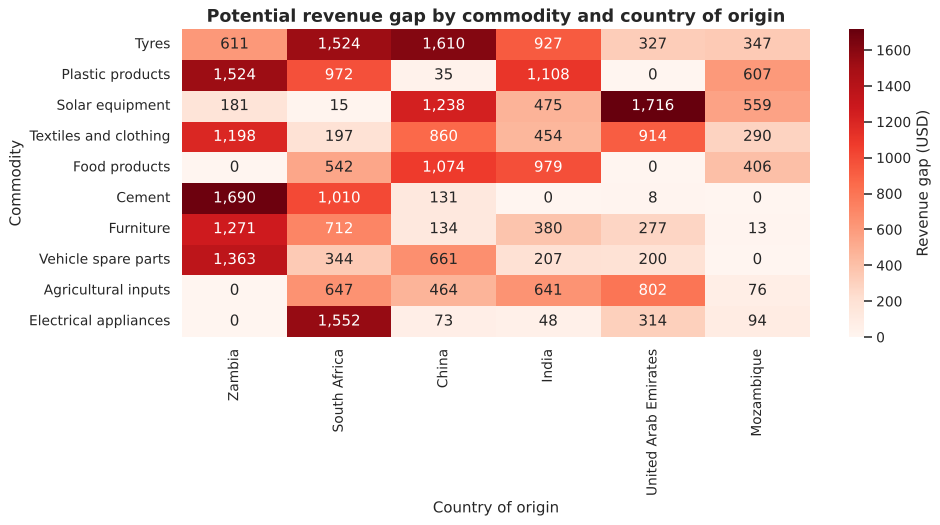

In [8]:
# Which country–commodity combinations concentrate the gap?
pivot = df.pivot_table(index='Commodity_Description', columns='Country_of_Origin',
                       values='Potential_Revenue_Gap_USD', aggfunc='sum', fill_value=0)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index,
                  pivot.sum().sort_values(ascending=False).index]
plt.figure(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='Reds', cbar_kws={'label': 'Revenue gap (USD)'})
plt.title('Potential revenue gap by commodity and country of origin', fontsize=14, fontweight='bold')
plt.xlabel('Country of origin'); plt.ylabel('Commodity')
plt.tight_layout()
plt.savefig('../reports/gap_heatmap_commodity_country.png', bbox_inches='tight')
plt.show()

top_pairs = (df.groupby(['Country_of_Origin', 'Commodity_Description'])['Potential_Revenue_Gap_USD']
               .sum().sort_values(ascending=False).head(5))
print("Top 5 country–commodity combinations:")
display(top_pairs.round(2).to_frame())

### Interpretation: country × commodity hotspots
* The heatmap shows that the leakage is concentrated in **specific combinations**, not whole countries. The top five are **UAE solar equipment ($1,716), Zambian cement ($1,690), Chinese tyres ($1,610), South African electrical appliances ($1,552) and South African tyres ($1,524)**.
* Some of these combinations are not visible from the separate country or commodity rankings. For example, UAE is only 5th by country, but its solar equipment is the single largest hotspot.

**Implication:** these specific **origin–commodity pairs** are concrete candidates for **valuation audits**. Each cell rests on only a handful of shipments (and the country and commodity effects are not statistically significant on their own), so treat them as **leads to investigate, not established risk rules**.

## 4. Which offence types cost the most?

,Cases,Revenue_Gap,Recovered,Recovery_Rate_%
Offence_Type,,,,
Under-valuation,11,7349.01,6202.23,84.40
Valuation adjustment,7,1908.73,1699.20,89.02
Misclassification,4,850.94,717.88,84.36
Incorrect declaration,2,266.73,227.00,85.10
Quantity discrepancy,1,233.01,210.68,90.42


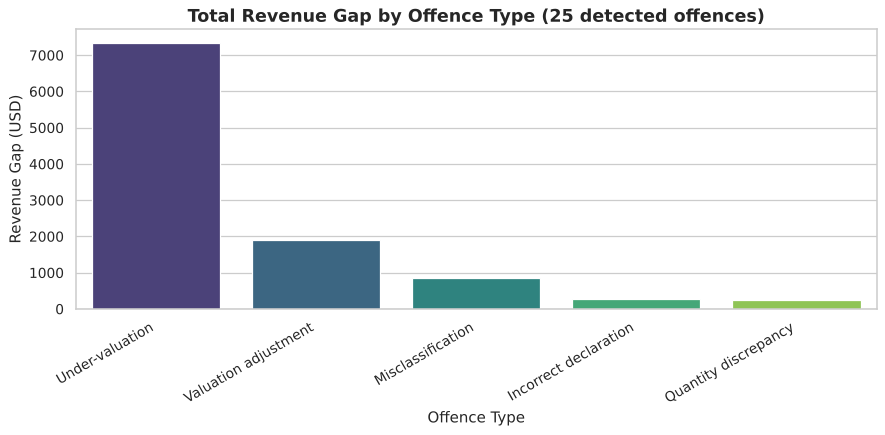

In [9]:
# Filter only rows where an offence was detected
offences_df = df[df['Offence_Detected'] == 'Yes']
offence_summary = offences_df.groupby('Offence_Type').agg(
    Cases=('Declaration_ID', 'count'),
    Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
    Recovered=('Additional_Revenue_Recovered_USD', 'sum')).sort_values('Revenue_Gap', ascending=False)
offence_summary['Recovery_Rate_%'] = offence_summary['Recovered'] / offence_summary['Revenue_Gap'] * 100
display(offence_summary.round(2))

# Create the plot (hue set explicitly to avoid the seaborn palette deprecation warning)
plt.figure(figsize=(10, 5))
sns.barplot(data=offence_summary.reset_index(), x='Offence_Type', y='Revenue_Gap',
            hue='Offence_Type', palette='viridis', legend=False)
plt.title('Total Revenue Gap by Offence Type (25 detected offences)', fontsize=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.ylabel('Revenue Gap (USD)')
plt.xlabel('Offence Type')
plt.tight_layout()

# Save the plot to the reports folder for the report and slides
plt.savefig('../reports/offence_types_chart.png')
plt.show()

### Interpretation: offence types
* **Under-valuation dominates:** 11 of the 25 offences and **$7,349 (69%) of the detected-offence gap**. Together with *valuation adjustment* (7 cases, $1,909), **valuation issues account for 87% of the detected gap**. Misclassification, incorrect declarations and quantity discrepancies are minor.
* **Recovery is consistently high (84–90%) for every offence type.** Once an offence is detected, the money is largely collected whatever the offence type.

**Implication:** valuation is the main risk. Customs should strengthen **valuation controls**: reference price databases for common goods (tyres, solar panels, plastics), and comparisons of declared unit values against market or import-database prices.

**Caution:** this chart only covers the **25 detected offences ($10,608)**, about a third of the total gap. The other $23,193 has no offence type because it was never detected. In the Power BI *"Revenue Gap by Offence Type"* visual, a large "No Offence" bar will appear unless it is filtered out. Filter it out and label the chart *"Detected offences only"*.

## 5. Revenue vs. monthly targets, and the trend over the year
The proposal asks us to *"compare revenue targets against actual collections"* and analyse trends. The `Monthly_Targets` sheet makes that possible.

In [10]:
monthly = df.groupby('Month').agg(
    Declared_Revenue=('Declared_Total_Revenue_USD', 'sum'),
    Assessed_Revenue=('Assessed_Total_Revenue_USD', 'sum'),
    Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
    Recovered=('Additional_Revenue_Recovered_USD', 'sum'),
    Declarations=('Declaration_ID', 'count')).reset_index()
monthly = monthly.merge(targets[['Month', 'Revenue_Target_USD']], on='Month', how='left')
monthly['Target_Achievement_%'] = monthly['Assessed_Revenue'] / monthly['Revenue_Target_USD'] * 100
monthly['Shortfall_vs_Target'] = monthly['Revenue_Target_USD'] - monthly['Assessed_Revenue']
display(monthly.round(2))

tot_target = monthly['Revenue_Target_USD'].sum()
print(f"\nAnnual target:            ${tot_target:,.2f}")
print(f"Annual assessed revenue:  ${total_assessed:,.2f}  ({total_assessed / tot_target * 100:.1f}% of target)")
print(f"Annual declared revenue:  ${total_declared:,.2f}  ({total_declared / tot_target * 100:.1f}% of target)")
print(f"Shortfall vs target:      ${tot_target - total_assessed:,.2f}")
print(f"Months meeting target:    {(monthly['Target_Achievement_%'] >= 100).sum()} of {len(monthly)}")
est_collected = total_declared + total_recovered
print(f"Estimated revenue actually secured (declared + recovered): ${est_collected:,.2f} "
      f"({est_collected / tot_target * 100:.1f}% of target)")
print(f"Correlation between monthly gap and number of declarations: "
      f"{monthly['Revenue_Gap'].corr(monthly['Declarations']):.2f}")

,Month,Declared_Revenue,Assessed_Revenue,Revenue_Gap,Recovered,Declarations,Revenue_Target_USD,Target_Achievement_%,Shortfall_vs_Target
0,2025-01,62518.50,65570.67,3052.17,1164.53,40,70531.13,92.97,4960.46
1,2025-02,65243.79,68993.53,3749.74,534.40,32,73925.18,93.33,4931.65
2,2025-03,70366.44,73019.68,2653.24,995.35,46,78641.62,92.85,5621.94
3,2025-04,70419.22,73974.33,3555.11,834.30,41,75353.16,98.17,1378.83
4,2025-05,58107.75,60102.60,1994.85,471.05,45,61790.35,97.27,1687.75
5,2025-06,70488.17,71276.46,788.29,471.83,30,78638.50,90.64,7362.04
6,2025-07,83381.99,86471.59,3089.60,619.44,44,96604.31,89.51,10132.72
7,2025-08,86560.74,88815.90,2283.03,789.93,44,101403.95,87.59,12588.05
8,2025-09,73305.51,75992.05,2955.94,1216.37,36,76013.78,99.97,21.73
9,2025-10,65011.50,67918.83,2907.33,1222.84,39,67922.23,99.99,3.40



Annual target:            $973,514.67
Annual assessed revenue:  $905,752.62  (93.0% of target)
Annual declared revenue:  $872,288.68  (89.6% of target)
Shortfall vs target:      $67,762.05
Months meeting target:    0 of 12
Estimated revenue actually secured (declared + recovered): $881,345.67 (90.5% of target)
Correlation between monthly gap and number of declarations: 0.18


### Interpretation: target performance (new analysis)
* **Forbes missed its revenue target in all 12 months.** Assessed revenue reached **$905,753 against a target of $973,515 (93.0%)**, a **shortfall of $67,762**.
* What importers **declared** covers only **89.6%** of target. Even counting the $9,057 recovered, the revenue **actually secured** is about **90.5% of target**. This is an estimate, because the data does not show how much of the Part-paid and Pending amounts was eventually paid.
* **Performance worsens in the high-target months**. July, August and November (targets of $96K–$101K) achieved only **88–90%**, while September and October came within a few dollars of target. The targets for peak months may be unrealistic, or capacity is stretched when volumes rise.
* **Context for the gap:** the full potential gap ($33,801) is about **half the shortfall vs target**. Closing every under-declaration would still not meet the targets, so leakage is a meaningful **contributor** to the shortfall, but not the whole story. Trade volumes and target-setting matter too.

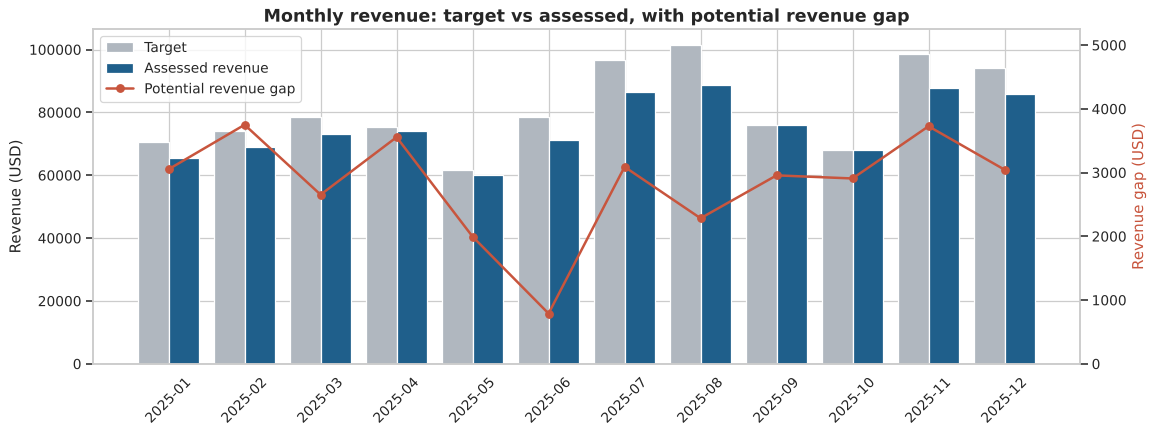

In [11]:
fig, ax1 = plt.subplots(figsize=(13, 5))
x = np.arange(len(monthly))
ax1.bar(x - 0.2, monthly['Revenue_Target_USD'], width=0.4, label='Target', color='#B0B7BF')
ax1.bar(x + 0.2, monthly['Assessed_Revenue'], width=0.4, label='Assessed revenue', color='#1F5F8B')
ax1.set_xticks(x); ax1.set_xticklabels(monthly['Month'], rotation=45)
ax1.set_ylabel('Revenue (USD)')
ax2 = ax1.twinx()
ax2.plot(x, monthly['Revenue_Gap'], color='#C8553D', marker='o', linewidth=2, label='Potential revenue gap')
ax2.set_ylabel('Revenue gap (USD)', color='#C8553D'); ax2.set_ylim(0, monthly['Revenue_Gap'].max() * 1.4)
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.title('Monthly revenue: target vs assessed, with potential revenue gap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/monthly_target_vs_actual.png', bbox_inches='tight')
plt.show()

### Interpretation: is the problem getting better or worse?
* The monthly gap moves between **about $0.8K (June) and $3.7K (February and November)**, with **no clear upward or downward trend** across the year. Leakage is a **persistent, steady problem**, not a one-off spike. Interventions therefore need to be ongoing controls, not a one-time crackdown.
* The gap is only weakly related to the number of declarations in the month (correlation 0.18), so busier months do not automatically produce more leakage.
* **June** stands out with an unusually low gap. **November** combines one of the highest gaps ($3,727) with almost **no recovery ($61)**, so November deserves a closer look.

*(The Power BI brief describes the line chart as covering an "8-month period"; it should say **12 months**.)*

## 6. Payment status

In [12]:
payment = df.groupby('Payment_Status').agg(
    Declarations=('Declaration_ID', 'count'),
    Assessed_Revenue=('Assessed_Total_Revenue_USD', 'sum'),
    Offences=('Offence_Detected', lambda s: (s == 'Yes').sum()),
    Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'))
payment['Share_of_Declarations_%'] = payment['Declarations'] / len(df) * 100
payment['Share_of_Assessed_Revenue_%'] = payment['Assessed_Revenue'] / total_assessed * 100
display(payment.round(2))

,Declarations,Assessed_Revenue,Offences,Revenue_Gap,Share_of_Declarations_%,Share_of_Assessed_Revenue_%
Payment_Status,,,,,,
Paid,419,796813.43,23,29208.63,87.29,87.97
Part-paid,39,69550.12,2,3885.20,8.12,7.68
Pending,22,39389.07,0,707.40,4.58,4.35


### Interpretation: payment status
* **87% of declarations are fully paid.** **39 are Part-paid and 22 are Pending**, and together they carry **$108,939 of assessed revenue (12%)**.
* These outstanding declarations are **mostly not offence cases** (only 2 of the 61 had an offence). Unpaid revenue is therefore a **general collection/cash-flow issue**, separate from the leakage problem, and should be reported separately.
* **Limitation:** the dataset has no "amount paid" column, so we cannot say how much of the $108,939 is actually outstanding, only that it sits in incompletely-paid declarations. The Power BI donut chart should show this caveat in a note.

## 7. Importer watchlist

In [13]:
importers = df.groupby('Importer_ID').agg(
    Declarations=('Declaration_ID', 'count'),
    Declarations_With_Gap=('Has_Revenue_Gap', lambda s: (s == 'Yes').sum()),
    Offences=('Offence_Detected', lambda s: (s == 'Yes').sum()),
    Inspections=('Inspection_Conducted', lambda s: (s == 'Yes').sum()),
    Revenue_Gap=('Potential_Revenue_Gap_USD', 'sum'),
    Recovered=('Additional_Revenue_Recovered_USD', 'sum'))
importers['Gap_Incidence_%'] = importers['Declarations_With_Gap'] / importers['Declarations'] * 100
watchlist = importers.sort_values('Revenue_Gap', ascending=False).head(10)
print("--- IMPORTER WATCHLIST (top 10 by potential revenue gap) ---")
display(watchlist.round(2))

top10_share = watchlist['Revenue_Gap'].sum() / total_gap * 100
repeat = (importers['Declarations_With_Gap'] >= 3).sum()
print(f"Top 10 of {len(importers)} importers account for {top10_share:.1f}% of the total gap.")
print(f"Importers with 3 or more under-declared shipments: {repeat}")
print(f"Importers with at least one under-declared shipment: {(importers['Declarations_With_Gap'] > 0).sum()}")

--- IMPORTER WATCHLIST (top 10 by potential revenue gap) ---


,Declarations,Declarations_With_Gap,Offences,Inspections,Revenue_Gap,Recovered,Gap_Incidence_%
Importer_ID,,,,,,,
Importer_025,6,3,1,2,2483.83,1216.37,50.00
Importer_004,10,2,2,5,2210.27,1846.46,20.00
Importer_046,10,3,0,1,1853.03,0.00,30.00
Importer_043,11,3,1,2,1612.26,919.33,27.27
Importer_042,9,4,2,2,1596.68,153.05,44.44
Importer_005,8,2,0,2,1412.48,0.00,25.00
Importer_022,8,4,0,2,1245.83,0.00,50.00
Importer_035,10,3,1,4,1118.20,471.83,30.00
Importer_021,13,2,0,4,980.38,0.00,15.38


Top 10 of 60 importers account for 45.8% of the total gap.
Importers with 3 or more under-declared shipments: 21
Importers with at least one under-declared shipment: 56


### Interpretation: importer watchlist (read with care)
* The **top 10 of 60 importers account for 45.8%** of the total gap, and **56 of 60 importers** had at least one under-declared shipment. **Under-declaration is widespread**, not confined to a few bad actors.
* **21 importers had 3 or more under-declared shipments.** This looks like "repeat offending", but notebook 03 shows it is **almost exactly what pure chance would produce** (20.2 expected if every declaration had the same 25.6% chance of a gap; p = 0.45). The top-10 concentration (45.8%) is also **no higher than chance** (about 49% when the gaps are shuffled randomly across importers). Past gaps **did not predict** future ones.
* Several watchlist importers had **no offence recorded and $0 recovered** (e.g. Importer_046, Importer_005, Importer_022, Importer_021, Importer_019). Their gaps were never detected, which illustrates the detection problem from Section 1.

**Implication:** the watchlist is useful for **follow-up of specific unrecovered amounts** (e.g. Importer_025: $2,484 gap, $1,216 recovered). However, in this dataset importer history is **not** a reliable predictor of future under-declaration, so a "persistent offender" story is not supported. In real ZIMRA data, importer history usually matters and should be re-tested. In Power BI, title the table *"Largest unrecovered gaps by importer"* rather than *"Worst repeat offenders"*.

## Summary of findings and implications

| # | Finding | Evidence | Implication / recommendation |
|---|---|---|---|
| 1 | Potential revenue gap of **$33,801 (3.7% of assessed revenue)**; only **26.8% recovered** | Section 1 | Leakage is modest overall but concentrated, so it is worth targeting |
| 2 | **65% of the gap is in shipments never inspected**; when offences *are* detected, **85% is recovered** | Section 1 | The problem is **detection**, not collection. Improve targeting rather than only chasing payments |
| 3 | **Risk profiling is inverted**: Low-risk shipments have the highest under-declaration rate (33%) and 58% of the gap, but only 12% are inspected; High-risk has the lowest hit rate (12%) | Section 2 | Recalibrate the risk rules; add random checks on Low-risk; build a data-driven risk score |
| 4 | **Zambia and South Africa = 45% of the gap**; Mozambique contributes least (differences in rate are *not* statistically significant, p = 0.51) | Section 3 | Monitor and audit; don't hard-code as risk rules yet |
| 5 | **Tyres** (largest gap), **plastic products** (38% under-declared), **solar equipment**; hotspots such as UAE solar, Zambian cement, Chinese tyres (not significant, p = 0.53) | Section 3 | Targeted valuation audits of these commodity–origin pairs as leads |
| 6 | **Valuation offences = 87% of the detected-offence gap** | Section 4 | Reference-price checks for high-risk goods |
| 7 | **Target missed in all 12 months** (93.0% achieved, $67.8K shortfall); worst in peak-target months; the gap explains about half the shortfall | Section 5 | Leakage is a contributor, not the only cause; review peak-month targets and capacity |
| 8 | **No trend** in the gap over 12 months | Section 5 | Leakage is persistent, so controls must be ongoing |
| 9 | **12% of assessed revenue** sits in Part-paid/Pending declarations, mostly unrelated to offences | Section 6 | Treat as a separate collections issue |
| 10 | **Top 10 importers = 46% of the gap**, but under-declaration is widespread (56 of 60 importers) and "repeat" counts match chance | Section 7 | Follow up the large unrecovered amounts; don't present as proven repeat offending |

**Corrections to carry into the report, README and Power BI brief:**
* The period is **January–December 2025 (12 months)**, not January–August / 8 months.
* Reframe the recovery recommendation: the low recovery rate is driven by **undetected** gaps, not by failed collection.
* Label the offence-type analysis as covering **detected offences only**.
* Inspection recommendation: do **not** simply move inspections away from High-risk. Instead, **add** random and analytics-driven checks for Low-risk shipments and re-rank risk using a data-driven score (notebook 03).

**Next step:** notebook **03_predictive_risk_model** builds and evaluates a model to predict which declarations will have a revenue gap. It covers the proposal's *Modelling and Evaluation* phase and the supervisor's "model performance" requirement, and it tests the statistical significance of the patterns above.